In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df = pd.read_csv("../data/Telco-Customer-Churn.csv")

print("databaset shape :", df.shape)

display(df.head())
display(df.info())

databaset shape : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None

In [69]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [71]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [72]:
df.describe(include="object")

/tmp/ipykernel_1859/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [73]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [116]:
print("duplicated rows:", df.duplicated().sum())

duplicated rows: 0


In [ ]:
for column in df.columns :
    print(f"\n{column}:")
    print(df[column].nunique())


customerID:
7043

gender:
2

SeniorCitizen:
2

Partner:
2

Dependents:
2

tenure:
73

PhoneService:
2

MultipleLines:
3

InternetService:
3

OnlineSecurity:
3

OnlineBackup:
3

DeviceProtection:
3

TechSupport:
3

StreamingTV:
3

StreamingMovies:
3

Contract:
3

PaperlessBilling:
2

PaymentMethod:
4

MonthlyCharges:
1585

TotalCharges:
6531

Churn:
2

Churn_Encoded:
2


In [76]:
print("Churn values:")
print(df["Churn"].value_counts())

print("\nContract values:")
print(df["Contract"].value_counts())

print("\nInternet Service values:")
print(df["InternetService"].value_counts())

print("\nPayment Method values:")
print(df["PaymentMethod"].value_counts())

Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Contract values:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

Internet Service values:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Payment Method values:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


In [77]:
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe())

            tenure  MonthlyCharges
count  7043.000000     7043.000000
mean     32.371149       64.761692
std      24.559481       30.090047
min       0.000000       18.250000
25%       9.000000       35.500000
50%      29.000000       70.350000
75%      55.000000       89.850000
max      72.000000      118.750000


In [78]:
blank_values = df[
    df["TotalCharges"].str.strip() == ""
]
print("blank total charges rows :", len(blank_values))

display(blank_values)

blank total charges rows : 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [79]:
zero_tenure = df[df["tenure"]== 0]

print("customers with zero tenure: ", len(zero_tenure))

display(zero_tenure)

customers with zero tenure:  11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [80]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [81]:
churn_percentage = (
    df["Churn"].value_counts(normalize= True)* 100
)
print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [82]:
df["TotalCharges"]= df["TotalCharges"].str.strip()

df["TotalCharges"] = df["TotalCharges"].replace("", np.nan)

print("missing values :")

print(df["TotalCharges"].isnull().sum())

missing values :
11


In [83]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors= "coerce"
)

print(df["TotalCharges"].dtype)

float64


In [84]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [85]:
print("missing values :", df["TotalCharges"].isnull().sum())

print("data type :", df["TotalCharges"].dtype)

print("zero TotalCharges :", (df["TotalCharges"] == 0).sum())

display(df[df["tenure"] == 0][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
])

missing values : 0
data type : float64
zero TotalCharges : 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,0.0
753,3115-CZMZD,0,20.25,0.0
936,5709-LVOEQ,0,80.85,0.0
1082,4367-NUYAO,0,25.75,0.0
1340,1371-DWPAZ,0,56.05,0.0
3331,7644-OMVMY,0,19.85,0.0
3826,3213-VVOLG,0,25.35,0.0
4380,2520-SGTTA,0,20.00,0.0
5218,2923-ARZLG,0,19.70,0.0
6670,4075-WKNIU,0,73.35,0.0


In [86]:
print("dataset shape:", df.shape)

print("\nmissing values :")
print(df.isnull().sum().sum())

print("\nDuplicate rows :")
print(df.duplicated().sum())
display(df.describe())

dataset shape: (7043, 21)

missing values :
0

Duplicate rows :
0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


# count customers by churn status

In [87]:
churn_counts = df["Churn"].value_counts()

print("churn counts :")
print(churn_counts)

churn counts :
Churn
No     5174
Yes    1869
Name: count, dtype: int64


# calculate churn percentage 

In [88]:
churn_percentage = df["Churn"].value_counts(normalize=True)* 100

print("\nchurn percentage :")
print(churn_percentage.round(2))


churn percentage :
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


customer churn Distribution
churn status
number of customers


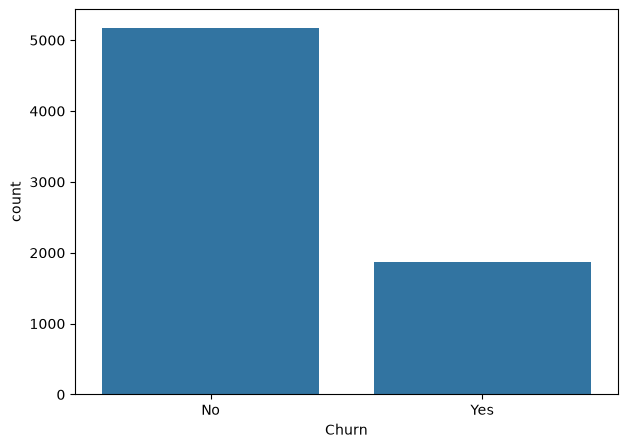

In [89]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data = df,
    x = "Churn"
)

print("customer churn Distribution")
print("churn status")
print("number of customers")

plt.show()

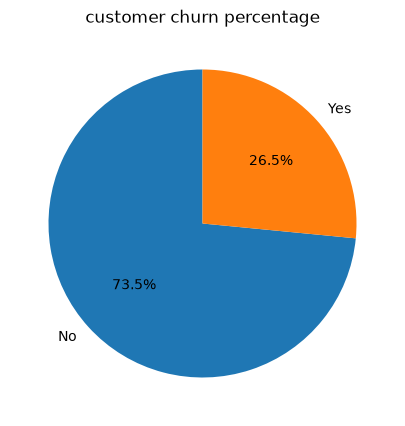

In [90]:
plt.figure(figsize=(7, 5))

churn_percentage.plot(
    kind= "pie",
    autopct = "%1.1f%%",
    startangle = 90
)

plt.title("customer churn percentage")
plt.ylabel("")
plt.show()


In [91]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print("customers count by contract :")
display(contract_churn)

customers count by contract :


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [92]:
contract_churn_rate = (df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean()* 100))

print("churn rate by contract:")
display(contract_churn_rate.round(2))

churn rate by contract:


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

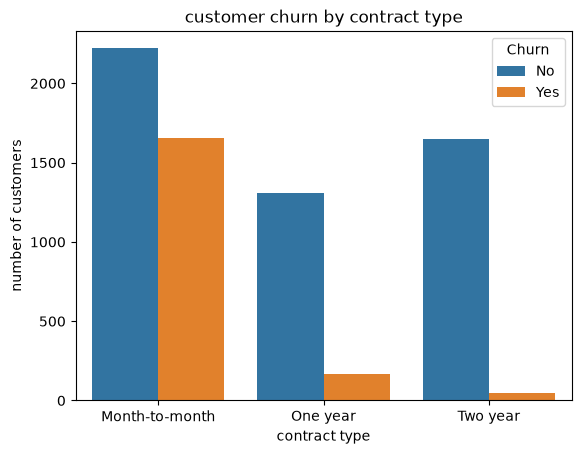

In [93]:
plt.Figure(figsize=(9, 5))

sns.countplot(
    data = df,
    x = "Contract",
    hue="Churn"
)

plt.title("customer churn by contract type")
plt.xlabel("contract type")
plt.ylabel("number of customers")

plt.show()

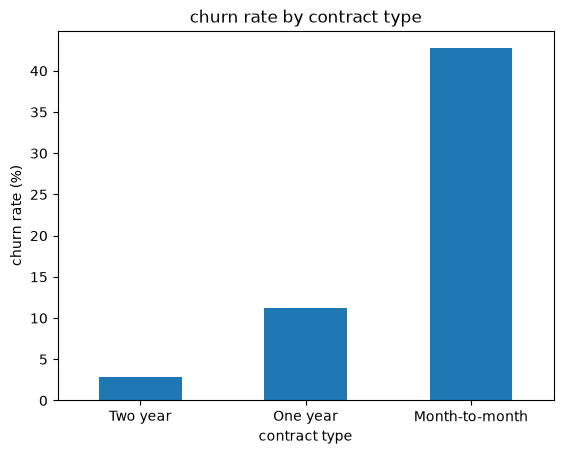

In [94]:
plt.Figure(figsize=(9, 5))

contract_churn_rate.sort_values().plot(
    kind= "bar"
)

plt.title("churn rate by contract type")
plt.xlabel("contract type")
plt.ylabel("churn rate (%)")
plt.xticks(rotation = 0)

plt.show()

In [95]:
tenure_churn = df.groupby("Churn")["tenure"].mean()

print("Average Tenure by status :")
display(tenure_churn.round(2))

Average Tenure by status :


Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

In [96]:
tenure_median = df.groupby("Churn")["tenure"].median()

print("median tenure by churn status :")
display(tenure_median)

median tenure by churn status :


Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

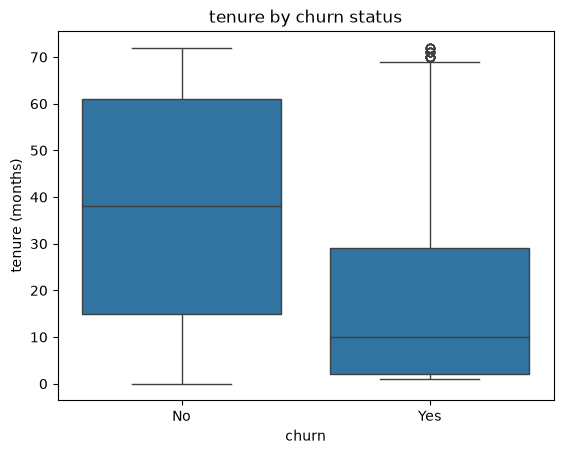

In [97]:
plt.Figure(figsize=(8, 5))

sns.boxplot(
    data = df,
    x = "Churn",
    y = "tenure"
)

plt.title("tenure by churn status")
plt.xlabel("churn")
plt.ylabel("tenure (months)")

plt.show()

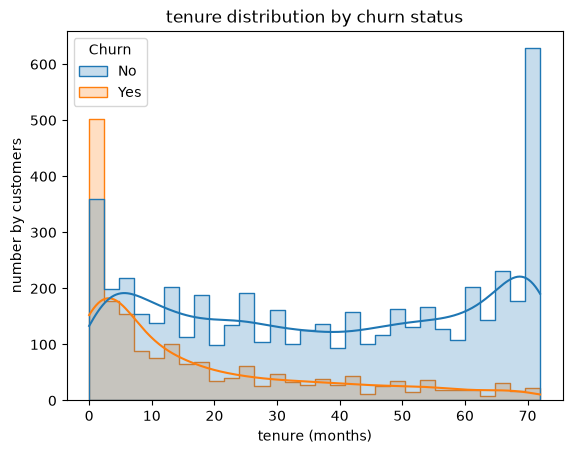

In [98]:
plt.Figure(figsize=(10, 5))

sns.histplot(
    data = df,
    x = "tenure",
    hue= "Churn",
    bins = 30,
    kde= True,
    element= "step"
)

plt.title("tenure distribution by churn status")
plt.xlabel("tenure (months)")
plt.ylabel("number by customers")

plt.show()

In [99]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)

print("customer count by Internet service :")
display(internet_churn)

customer count by Internet service :


Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [100]:
internet_churn_rate = (
    df.groupby("InternetService")["Churn"].apply(lambda x: (x == "Yes").mean()* 100)
)

print("Churn rate by internet service :")
display(internet_churn_rate.round(2))

Churn rate by internet service :


InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

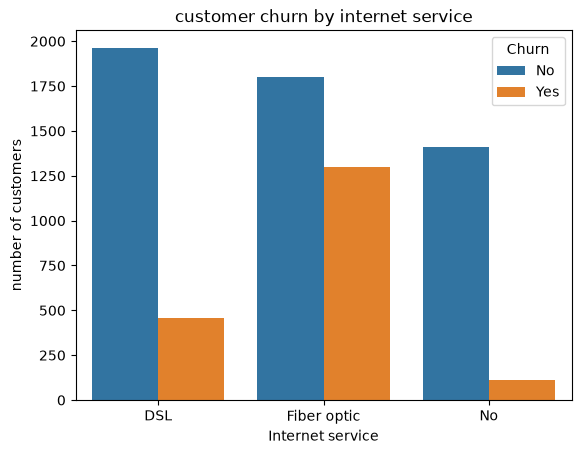

In [101]:
plt.Figure(figsize=(9, 5))

sns.countplot(
    data = df,
    x = "InternetService",
    hue = "Churn"
)

plt.title("customer churn by internet service")
plt.xlabel("Internet service")
plt.ylabel("number of customers")

plt.show()

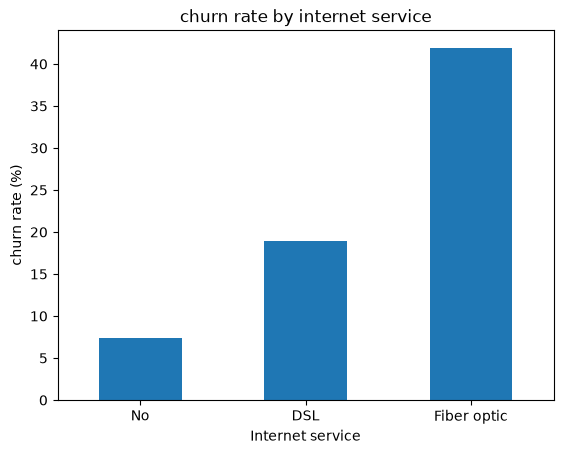

In [102]:
plt.Figure(figsize=(9, 5))

internet_churn_rate.sort_values().plot(kind="bar")

plt.title("churn rate by internet service")
plt.xlabel("Internet service")
plt.ylabel("churn rate (%)")
plt.xticks(rotation = 0)

plt.show()

In [103]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

print("customer count by payment method :")

display(payment_churn)

customer count by payment method :


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [104]:
payment_churn_rate = (
    df.groupby("PaymentMethod")["Churn"].apply(lambda x: (x == "Yes").mean()* 100)
)
print("churn rate by payment method")
display(payment_churn_rate.round(2))

churn rate by payment method


PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64

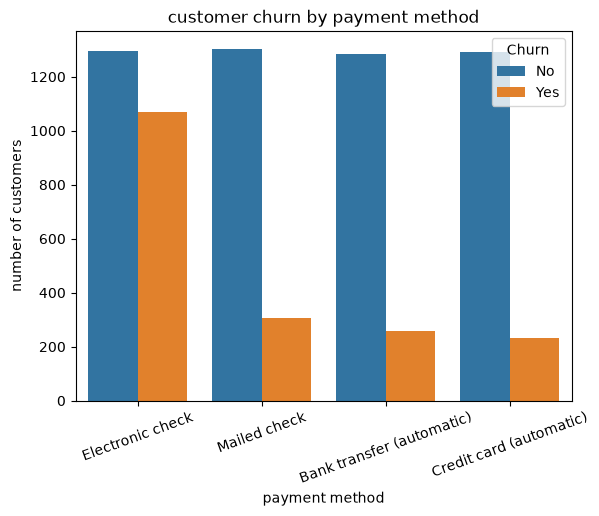

In [105]:
plt.Figure(figsize=(11, 5))
sns.countplot(
    data = df,
    x = "PaymentMethod",
    hue= "Churn"
)
plt.title("customer churn by payment method")
plt.xlabel("payment method")
plt.ylabel("number of customers")
plt.xticks(rotation = 20)

plt.show()

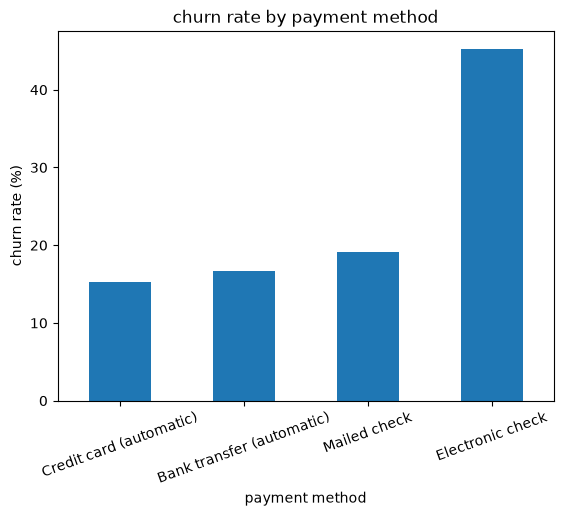

In [106]:
plt.Figure(figsize=(11, 5))

payment_churn_rate.sort_values().plot(kind = "bar")

plt.title("churn rate by payment method")
plt.xlabel("payment method")
plt.ylabel("churn rate (%)")
plt.xticks(rotation = 20)

plt.show()

In [107]:
monthly_charges_mean = df.groupby("Churn")["MonthlyCharges"].mean()

print("average monthly charges churn: ")

display(monthly_charges_mean.round(2))

average monthly charges churn: 


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

In [108]:
monthly_charges_median = df.groupby("Churn")["MonthlyCharges"].median()

print("median monthly charges by churn:")
display(monthly_charges_median.round(2))

median monthly charges by churn:


Churn
No     64.43
Yes    79.65
Name: MonthlyCharges, dtype: float64

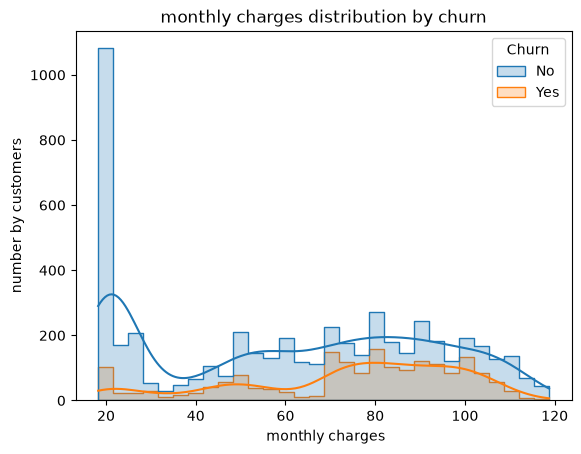

In [109]:
plt.Figure(figsize=(10, 5))

sns.histplot(
    data = df,
    x = "MonthlyCharges",
    hue= "Churn",
    bins = 30,
    kde= True,
    element= "step"
)

plt.title("monthly charges distribution by churn")
plt.xlabel(" monthly charges")
plt.ylabel("number by customers")

plt.show()

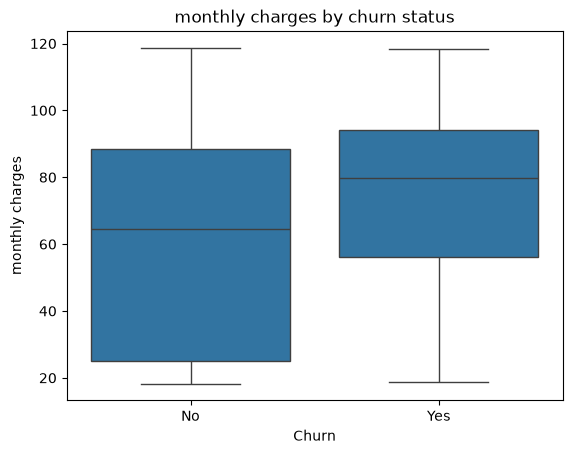

In [110]:
plt.Figure(figsize=(8, 5))

sns.boxplot(
    data = df,
    x = "Churn",
    y = "MonthlyCharges"
)

plt.title("monthly charges by churn status")
plt.xlabel("Churn")
plt.ylabel("monthly charges")

plt.show()

In [111]:
summary = pd.DataFrame({
    "Factor": [
        "Contract",
        "Contract",
        "Contract",
        "Internet Service",
        "Internet Service",
        "Internet Service",
        "Payment Method",
        "Payment Method",
        "Payment Method",
        "Payment Method"
    ],
    "Category": [
        "Month-to-month",
        "One year",
        "Two year",
        "DSL",
        "Fiber optic",
        "No Internet",
        "Bank transfer (automatic)",
        "Credit card (automatic)",
        "Electronic check",
        "Mailed check"
    ],
    "Churn rate (%)": [
        42.71,
        11.27,
        2.83,
        18.96,
        41.89,
        7.40,
        16.71,
        15.24,
        45.29,
        19.11
    ]
})

display(summary)

,Factor,Category,Churn rate (%)
0,Contract,Month-to-month,42.71
1,Contract,One year,11.27
2,Contract,Two year,2.83
3,Internet Service,DSL,18.96
4,Internet Service,Fiber optic,41.89
5,Internet Service,No Internet,7.40
6,Payment Method,Bank transfer (automatic),16.71
7,Payment Method,Credit card (automatic),15.24
8,Payment Method,Electronic check,45.29
9,Payment Method,Mailed check,19.11


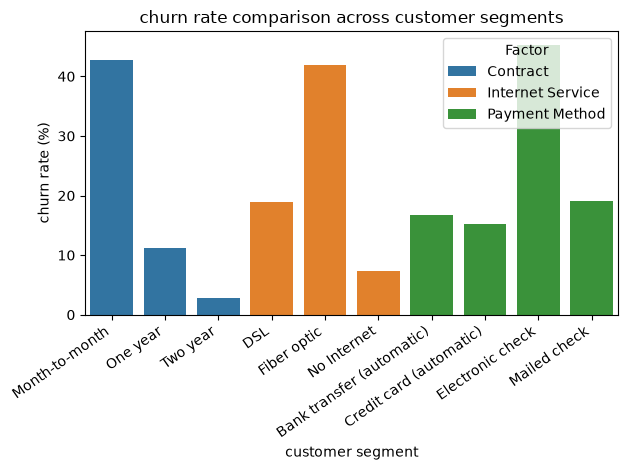

In [112]:
plt.Figure(figsize=(12, 6))

sns.barplot(
    data = summary,
    x = "Category",
    y = "Churn rate (%)",
    hue= "Factor"
)

plt.title("churn rate comparison across customer segments")
plt.xlabel("customer segment")
plt.ylabel("churn rate (%)")
plt.xticks(rotation = 35, ha = "right")

plt.legend(title = "Factor")
plt.tight_layout()
plt.show()

In [113]:
df["Churn_Encoded"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [114]:
correlation = df[
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn_Encoded"]
].corr()

display(correlation.round(3))

,tenure,MonthlyCharges,TotalCharges,Churn_Encoded
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.198
Churn_Encoded,-0.352,0.193,-0.198,1.000


In [124]:
import sqlite3

#creat SQLite database
conn = sqlite3.connect("../data/customer_churn.db")

#copy dataframe into SQL table
df.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

print("Data successfully saved to SQLite database.")

Data successfully saved to SQLite database.


In [125]:
query = """
SELECT COUNT(*) AS total_customers
FROM customers;
"""

result = pd.read_sql_query(query, conn)
display(result)

,total_customers
0,7043


In [126]:
query = """
SELECT
    Churn,
    COUNT(*) AS customer_count
FROM customers
GROUP BY Churn;
"""
result = pd.read_sql_query(query, conn)

display(result)

,Churn,customer_count
0,No,5174
1,Yes,1869


In [127]:
query = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS
churned_customers,
    ROUND(
        100.0 * SUM (CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) /
COUNT(*),
    2
    ) AS Churn_rate
FROM customers
GROUP BY Contract
ORDER BY churn_rate DESC;
"""

result = pd.read_sql_query(query, conn)

display(result)

,Contract,total_customers,churned_customers,Churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [128]:
query = """
SELECT
    PaymentMethod,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY PaymentMethod
ORDER BY churn_rate DESC;
"""

result = pd.read_sql_query(query, conn)

display(result)

,PaymentMethod,total_customers,churned_customers,churn_rate
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


In [129]:
query = """
SELECT
    InternetService,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS churn_rate
FROM customers
GROUP BY InternetService
ORDER BY churn_rate DESC;
"""

result = pd.read_sql_query(query, conn)

display(result)

,InternetService,total_customers,churned_customers,churn_rate
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


In [130]:
conn.close()